In [99]:
import matplotlib.pyplot as plt
from banana_ml.data.loader import load_raw_data
from banana_ml.data.validation import (
    validate_dataset,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
import seaborn as sns
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate


## 1. Analyse univariée

L'analyse univariée consiste à étudier chaque variable individuellement afin de comprendre sa distribution, sa tendance centrale, sa dispersion et la présence éventuelle de valeurs extrêmes.

Pour les variables numériques, nous analyserons notamment :

- le nombre d'observations ;
- la moyenne ;
- l'écart-type ;
- les quartiles ;
- le minimum et le maximum ;
- la distribution des valeurs ;
- les éventuelles valeurs aberrantes.

In [60]:


df = load_raw_data()
validate_dataset(df)

df.head()

,temperature,humidity,ethylene,O2,CO2,days,brix,pH,firmness,color_index,quality
0,12.26,95.85,8.77,7.79,6.31,16.04,13.27,4.66,6.89,4.24,moyen
1,14.57,78.39,6.28,8.54,7.70,20.63,15.35,4.73,6.54,5.12,moyen
2,13.11,89.79,0.15,2.76,4.68,13.63,11.78,5.20,9.04,3.80,bon
3,13.63,91.69,0.69,4.02,2.55,7.07,8.66,5.16,9.28,3.80,bon
4,23.19,97.87,18.78,19.99,13.38,27.02,17.67,4.30,2.69,7.37,mauvais


## 1. Analyse univariée

L'analyse univariée consiste à étudier chaque variable individuellement afin de comprendre sa distribution, sa tendance centrale, sa dispersion et la présence éventuelle de valeurs extrêmes.

Pour les variables numériques, nous analyserons notamment :

- le nombre d'observations ;
- la moyenne ;
- l'écart-type ;
- les quartiles ;
- le minimum et le maximum ;
- la distribution des valeurs ;
- les éventuelles valeurs aberrantes.

In [61]:
numeric_columns = df.select_dtypes(include="number").columns

stats = df[numeric_columns].describe().T

stats

,count,mean,std,min,25%,50%,75%,max
temperature,4500.0,13.928389,4.415049,5.01,11.4900,13.520,15.8700,25.00
humidity,4500.0,86.325353,12.816435,50.03,80.4375,90.215,96.3325,100.00
ethylene,4500.0,7.067758,6.387429,0.10,0.7600,5.705,12.4925,20.00
O2,4500.0,8.850998,5.422109,2.00,4.2800,7.450,12.8050,20.99
CO2,4500.0,8.692567,5.169798,2.00,4.2500,7.525,12.6800,20.00
days,4500.0,19.599736,11.177743,0.02,10.5100,19.490,28.5750,40.00
brix,4500.0,15.128664,5.484809,5.56,10.4500,14.955,19.7725,26.33
pH,4500.0,4.660864,0.551375,3.50,4.2400,4.740,5.1200,5.50
firmness,4500.0,5.485629,2.613258,1.01,3.1800,5.495,7.7125,10.00
color_index,4500.0,4.991851,1.748739,2.00,3.4800,5.000,6.5100,8.00


On voit déjà que les variables couvrent l'ensemble des états physiologiques nécessaires à notre problème :
Conditions favorables
       ↓
    BON
       ↓
    MOYEN
       ↓
   MAUVAIS

### 1.2 Distribution des variables numériques

L'étude des distributions permet d'identifier la forme des variables,
leur dispersion ainsi que la présence éventuelle de valeurs extrêmes.

Des histogrammes sont utilisés pour visualiser la fréquence des observations
pour chacune des variables numériques.

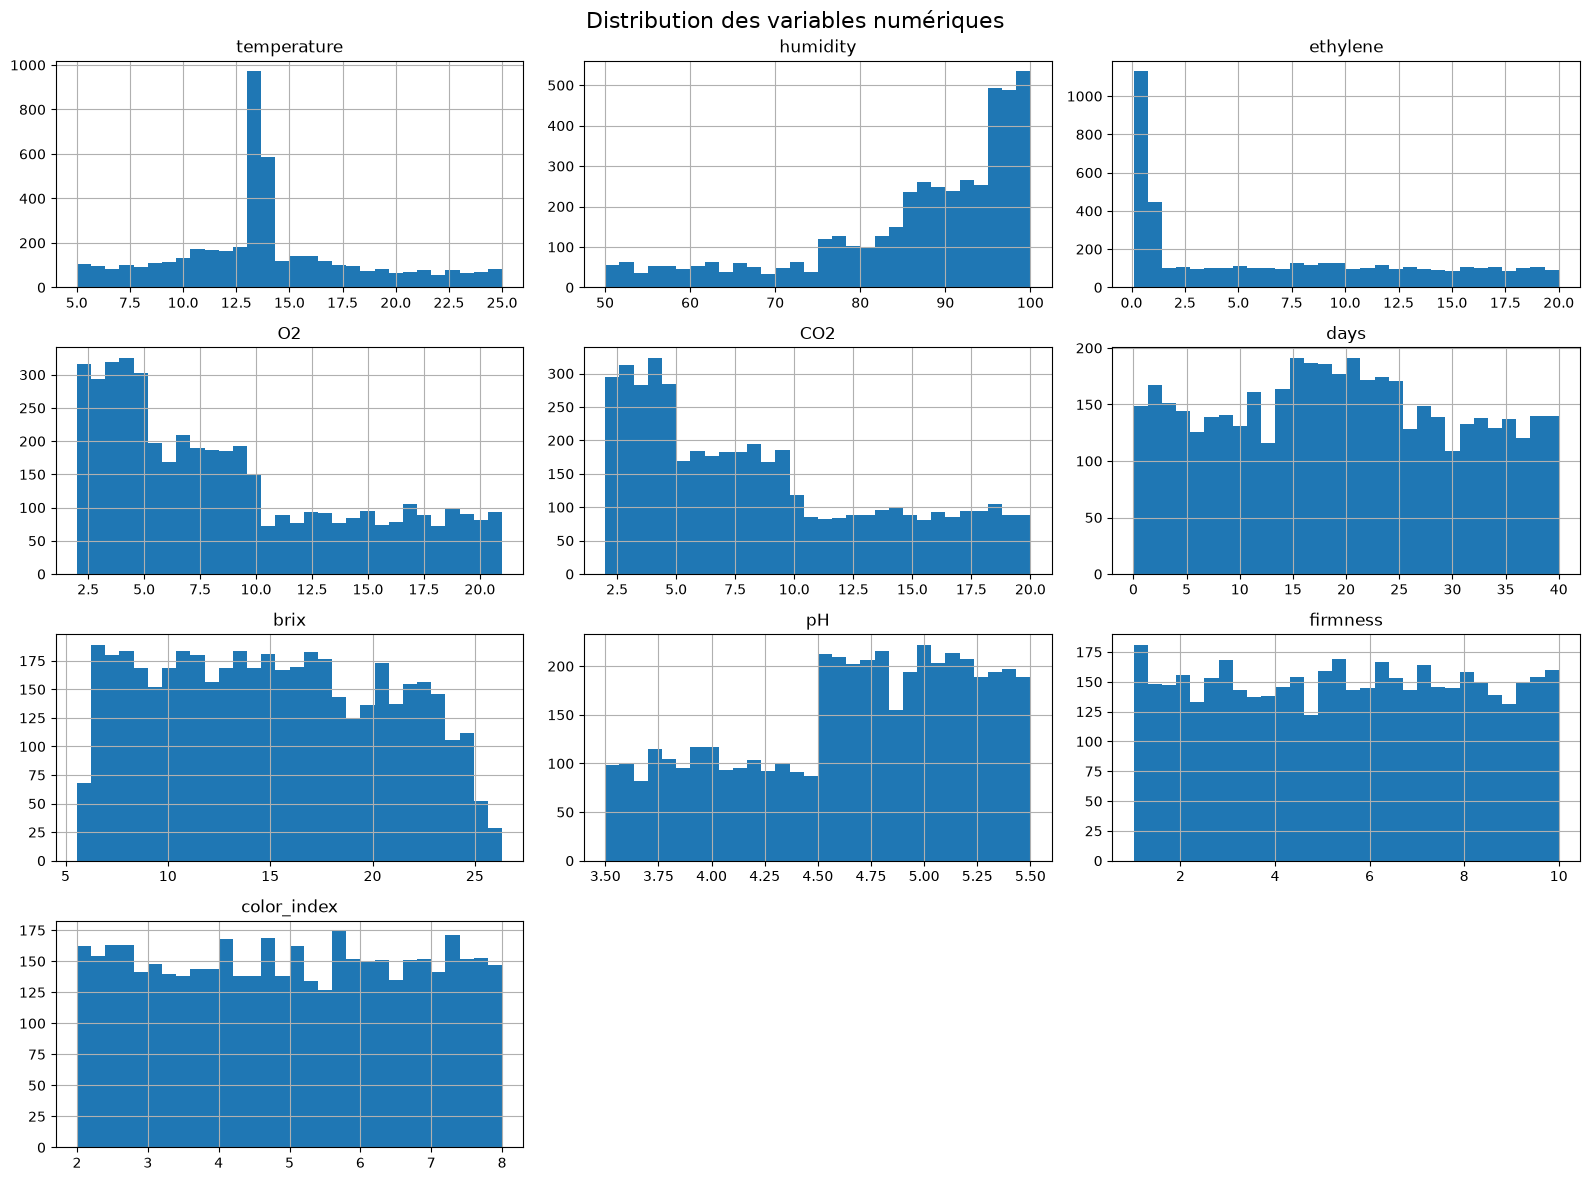

In [62]:
numeric_columns = df.select_dtypes(include="number").columns

df[numeric_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle(
    "Distribution des variables numériques",
    fontsize=16
)

plt.tight_layout()
plt.show()

Globalement, les variables présentent des distributions hétérogènes. Certaines variables, notamment l'éthylène, l'O₂ et le CO₂, présentent une asymétrie positive, tandis que d'autres couvrent relativement uniformément leur domaine de variation.
Ces observations permettent de mieux caractériser le jeu de données avant la modélisation. Elles devront être prises en compte lors des étapes de prétraitement et de sélection des modèles. Une analyse complémentaire à l'aide de boxplots permettra notamment d'étudier la dispersion des variables et d'identifier d'éventuelles valeurs extrêmes. L'analyse bivariée permettra ensuite d'étudier les relations entre les variables et la qualité des bananes.

### 1.3 Détection des valeurs extrêmes

Les boxplots permettent d'observer la dispersion des variables numériques
et d'identifier d'éventuelles observations extrêmes.

Une valeur identifiée comme extrême statistiquement n'est pas nécessairement
une erreur : elle peut représenter une condition réelle de stockage.

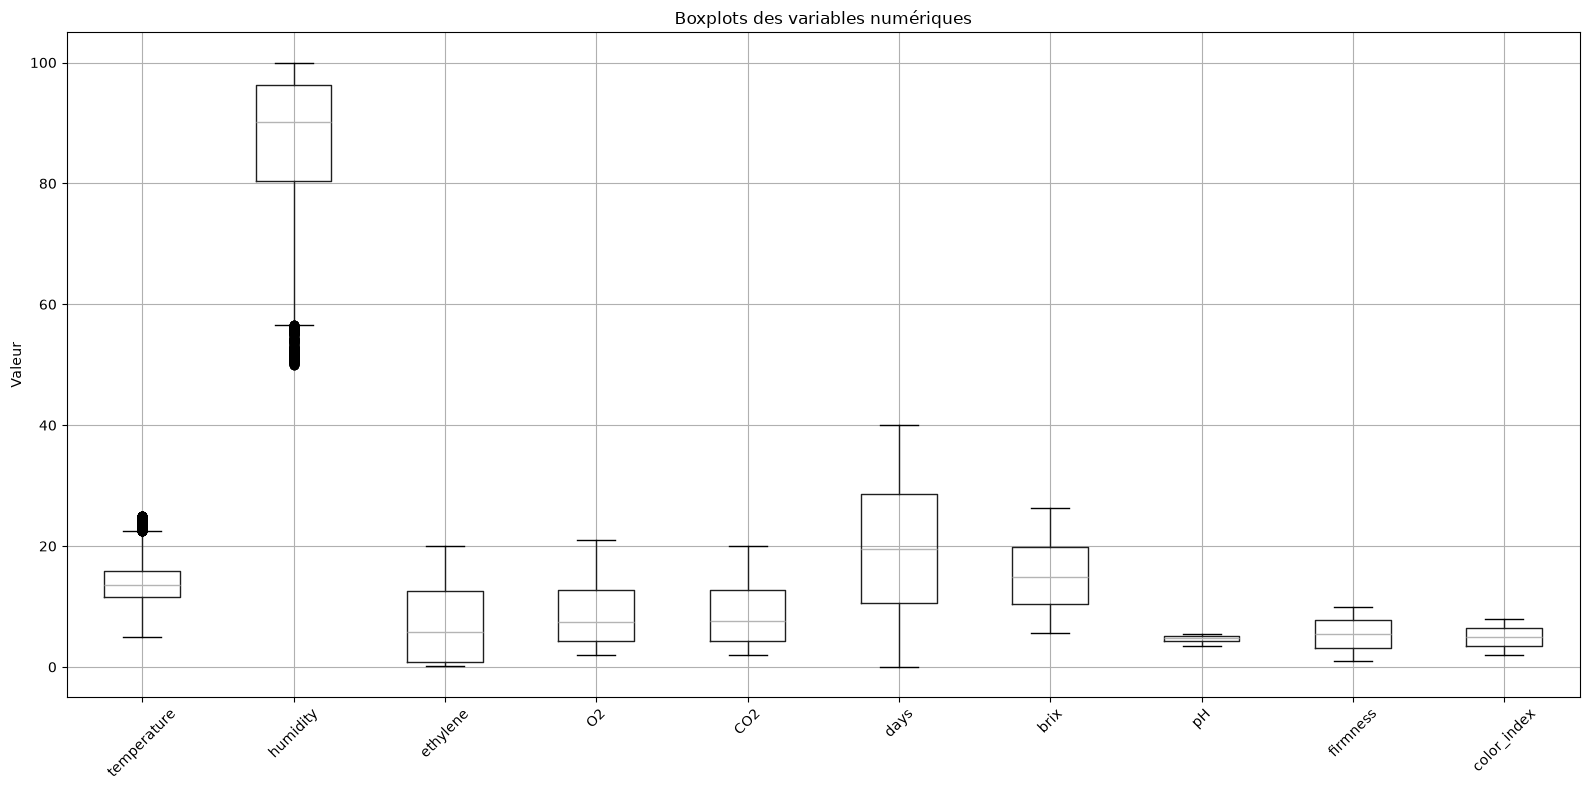

In [63]:
numeric_columns = df.select_dtypes(include="number").columns

plt.figure(figsize=(16, 8))

df[numeric_columns].boxplot()

plt.title("Boxplots des variables numériques")
plt.ylabel("Valeur")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Les boxplots mettent en évidence une dispersion importante pour certaines variables, notamment humidity, days, brix et ethylene. Des observations atypiques sont également visibles pour plusieurs variables, en particulier humidity et temperature.
Toutefois, ces observations ne sont pas automatiquement considérées comme des erreurs. Dans le contexte du stockage post-récolte, des valeurs éloignées de la zone centrale peuvent représenter des conditions environnementales défavorables ou des stades avancés de maturation. Elles peuvent donc contenir une information importante pour la prédiction de la qualité.
Par conséquent, aucune suppression automatique des valeurs atypiques ne sera effectuée à ce stade. Leur impact sera évalué lors des étapes suivantes de l'analyse et de la modélisation.

### 1.4 Distribution de la variable cible

La variable `quality` représente la classe de qualité des bananes.
Elle possède trois modalités : `bon`, `moyen` et `mauvais`.

L'analyse de sa distribution permet notamment de vérifier l'équilibre
des classes avant la phase de modélisation.

In [64]:
quality_counts = df["quality"].value_counts()

quality_counts

quality
moyen      1500
bon        1500
mauvais    1500
Name: count, dtype: int64

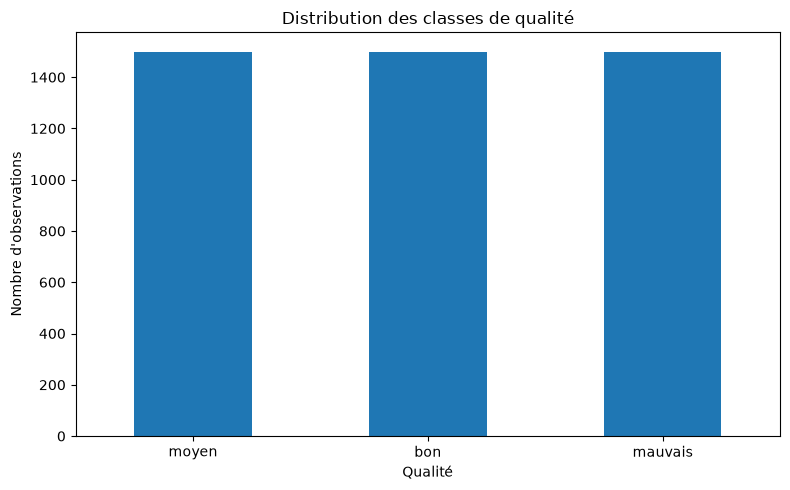

In [65]:
quality_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution des classes de qualité")
plt.xlabel("Qualité")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

La variable cible quality présente une distribution parfaitement équilibrée entre les trois classes bon, moyen et mauvais. Chaque classe contient 1 500 observations, soit environ 33,3 % de l'ensemble des données.
Aucun déséquilibre significatif des classes n'est donc observé. Cette répartition équilibrée constitue un avantage pour l'apprentissage des modèles de classification, puisqu'aucune classe n'est fortement sous-représentée. Il ne sera ainsi pas nécessaire d'appliquer, à ce stade, des techniques spécifiques de rééquilibrage telles que le sur-échantillonnage ou le sous-échantillonnage.

## 2. Analyse bivariée

L'analyse bivariée vise à étudier les relations entre les variables
explicatives et la variable cible `quality`.

L'objectif est d'identifier les variables présentant des différences
significatives entre les trois niveaux de qualité : `bon`, `moyen` et
`mauvais`.

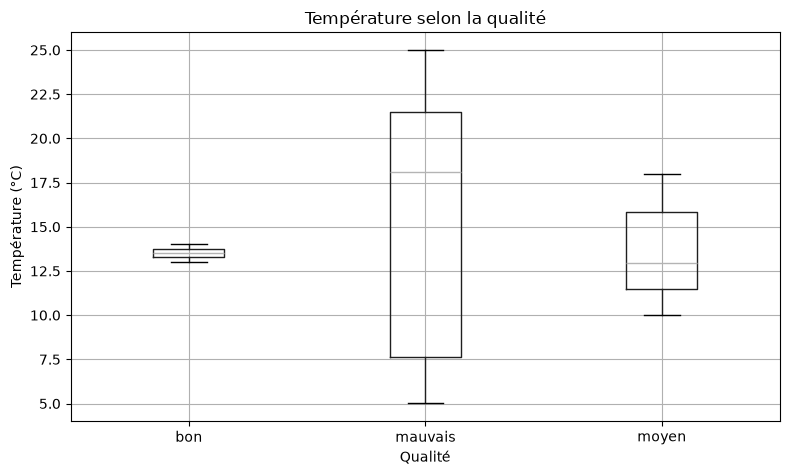

In [66]:
df.boxplot(
    column="temperature",
    by="quality",
    figsize=(8, 5)
)

plt.title("Température selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Température (°C)")
plt.tight_layout()
plt.show()

La température semble être une variable discriminante pour la qualité. Les produits de bonne qualité présentent des températures relativement concentrées autour de 13–14 °C, tandis que la classe « mauvais » se caractérise par une dispersion beaucoup plus importante et une médiane plus élevée. La classe « moyen » présente des valeurs intermédiaires. Ces observations suggèrent qu’une température éloignée des conditions optimales de conservation peut être associée à une dégradation de la qualité. La température apparaît ainsi comme une variable potentiellement importante pour la classification de la qualité.

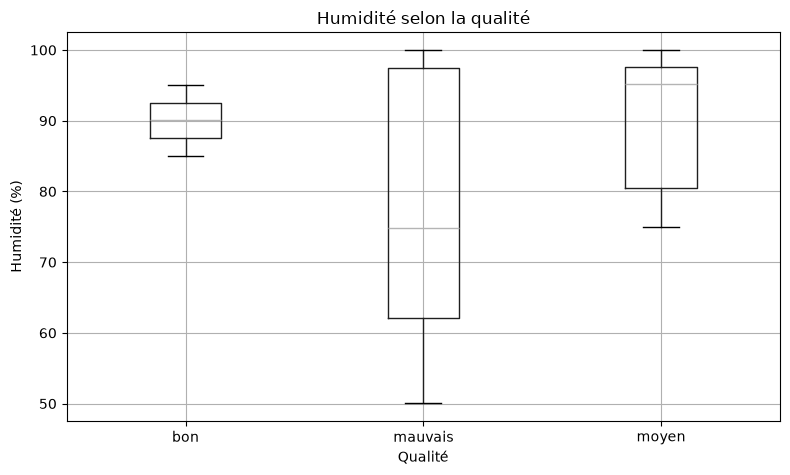

In [67]:
df.boxplot(
    column="humidity",
    by="quality",
    figsize=(8, 5)
)

plt.title("Humidité selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Humidité (%)")
plt.tight_layout()
plt.show()

L'humidité présente également une relation importante avec la classe de qualité. Les produits de bonne qualité présentent une humidité relativement concentrée autour de la zone optimale, avec une médiane proche de 90 %. La classe « mauvais » présente une dispersion beaucoup plus importante et des valeurs d'humidité pouvant être nettement inférieures à la zone optimale. La classe « moyen » présente quant à elle des valeurs généralement plus élevées, avec une concentration importante autour de la partie supérieure de l'échelle. Ces observations montrent que des conditions d'humidité éloignées de la plage optimale peuvent être associées à une dégradation de la qualité. L'humidité apparaît ainsi comme une variable potentiellement discriminante pour la classification.

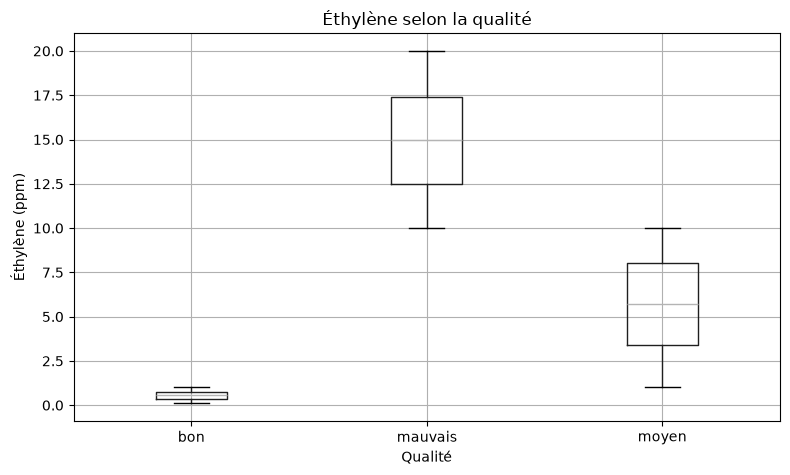

In [68]:
df.boxplot(
    column="ethylene",
    by="quality",
    figsize=(8, 5)
)

plt.title("Éthylène selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Éthylène (ppm)")
plt.tight_layout()
plt.show()

L'éthylène présente une relation très marquée avec la classe de qualité. Les produits de bonne qualité présentent des concentrations très faibles en éthylène, généralement inférieures à 1 ppm. La classe « moyen » présente des concentrations intermédiaires, comprises principalement entre 1 et 10 ppm, tandis que la classe « mauvais » présente des concentrations nettement plus élevées, généralement supérieures à 10 ppm. Les médianes des trois classes sont également fortement différenciées. Ces observations sont cohérentes avec les règles physiologiques utilisées pour définir les classes et montrent que l'éthylène constitue une variable fortement discriminante pour la classification de la qualité.

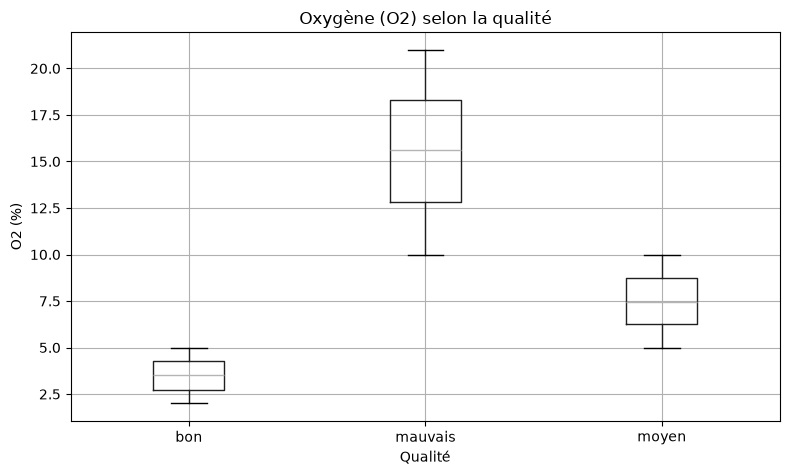

In [69]:
df.boxplot(
    column="O2",
    by="quality",
    figsize=(8, 5)
)

plt.title("Oxygène (O2) selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("O2 (%)")
plt.tight_layout()
plt.show()

La concentration en oxygène (O2) présente une relation importante avec la qualité. Les produits de bonne qualité présentent des concentrations relativement faibles, principalement comprises entre 2 % et 5 %, avec une médiane proche de 3,5 %. La classe « moyen » présente des valeurs intermédiaires, généralement comprises entre 5 % et 10 %. À l’inverse, la classe « mauvais » se caractérise par des concentrations nettement plus élevées, supérieures à 10 %, avec une dispersion importante. Les trois distributions sont ainsi clairement différenciées, ce qui indique que la concentration en oxygène constitue une variable fortement discriminante pour la classification de la qualité.

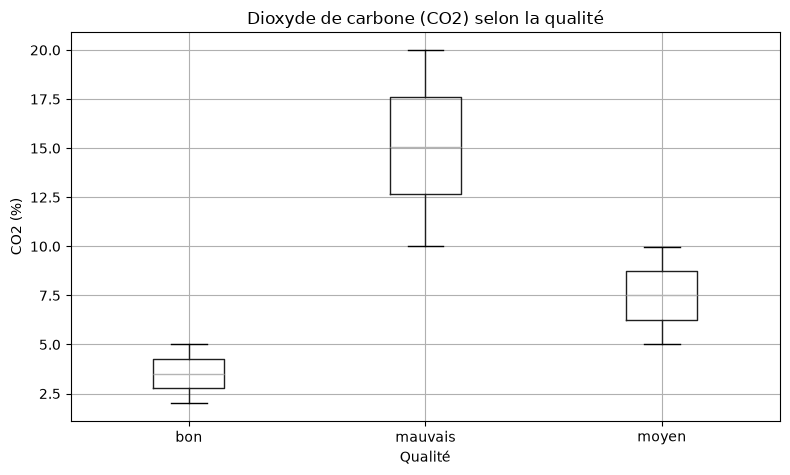

In [70]:
df.boxplot(
    column="CO2",
    by="quality",
    figsize=(8, 5)
)

plt.title("Dioxyde de carbone (CO2) selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("CO2 (%)")
plt.tight_layout()
plt.show()

La concentration en dioxyde de carbone (CO2) présente une relation importante avec la qualité. Les produits de bonne qualité présentent des concentrations relativement faibles, principalement comprises entre 2 % et 5 %, avec une médiane proche de 3,5 %. La classe « moyen » présente des concentrations intermédiaires, généralement comprises entre 5 % et 10 %. À l'inverse, la classe « mauvais » se caractérise par des concentrations nettement plus élevées, supérieures à 10 %, avec une médiane proche de 15 %. Les trois distributions sont ainsi clairement différenciées. Le CO2 apparaît donc comme une variable fortement discriminante pour la classification de la qualité.

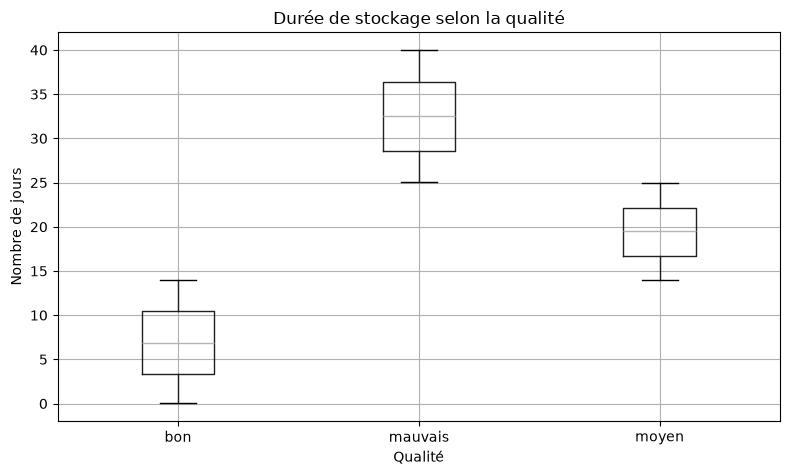

In [71]:
df.boxplot(
    column="days",
    by="quality",
    figsize=(8, 5)
)

plt.title("Durée de stockage selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Nombre de jours")
plt.tight_layout()
plt.show()

La durée de stockage (days) présente une relation très forte avec la classe de qualité. Les produits de bonne qualité sont principalement associés à une durée de stockage inférieure à 14 jours, avec une médiane proche de 7 jours. La classe « moyen » correspond à des durées intermédiaires, comprises approximativement entre 14 et 25 jours, avec une médiane proche de 20 jours. Enfin, la classe « mauvais » est associée aux durées de stockage les plus longues, généralement supérieures à 25 jours, avec une médiane proche de 32,5 jours. Les trois distributions sont clairement séparées, ce qui montre que la durée de stockage constitue une variable fortement discriminante pour la classification de la qualité.

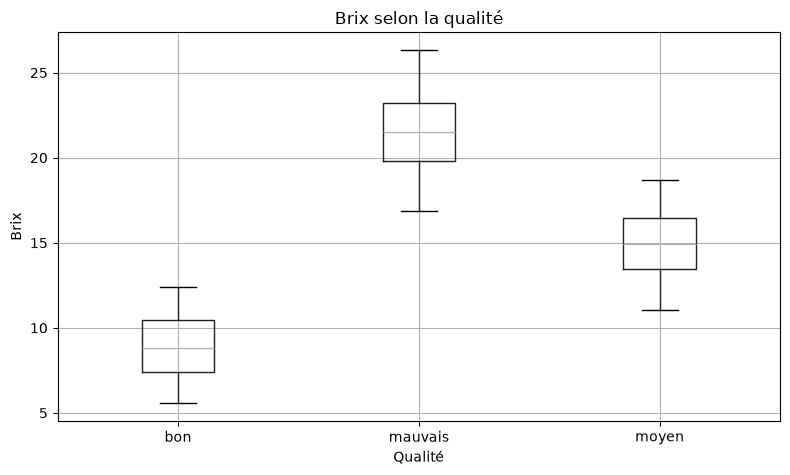

In [72]:
df.boxplot(
    column="brix",
    by="quality",
    figsize=(8, 5)
)

plt.title("Brix selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Brix")
plt.tight_layout()
plt.show()

Le taux de Brix présente une relation très forte avec la classe de qualité. Les produits de bonne qualité présentent des valeurs relativement faibles, principalement comprises entre environ 6 et 12, avec une médiane proche de 9. La classe « moyen » présente des valeurs intermédiaires, généralement comprises entre 12 et 18, avec une médiane proche de 15. Enfin, la classe « mauvais » présente les valeurs de Brix les plus élevées, généralement supérieures à 18, avec une médiane proche de 21,5. Les trois distributions sont clairement séparées, ce qui indique que le Brix constitue une variable fortement discriminante pour la classification de la qualité

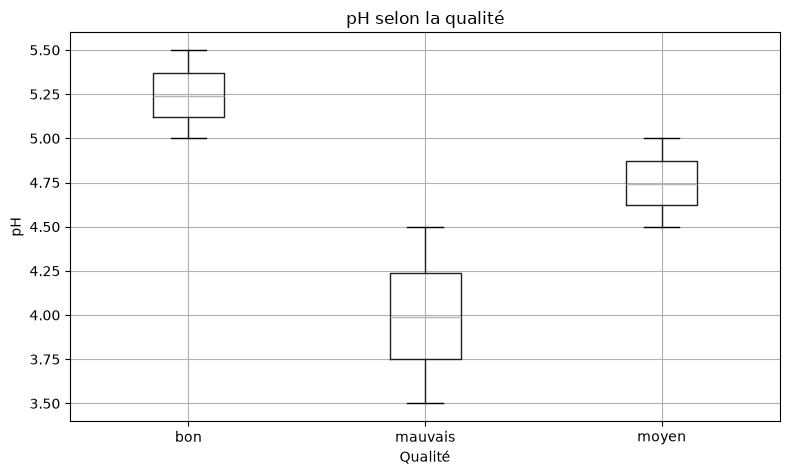

In [73]:
df.boxplot(
    column="pH",
    by="quality",
    figsize=(8, 5)
)

plt.title("pH selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("pH")
plt.tight_layout()
plt.show()

Le pH présente une relation très nette avec la classe de qualité. Les produits de bonne qualité présentent les valeurs de pH les plus élevées, principalement comprises entre 5,0 et 5,5, avec une médiane proche de 5,25. La classe « moyen » présente des valeurs intermédiaires, comprises approximativement entre 4,5 et 5,0, avec une médiane proche de 4,75. Enfin, la classe « mauvais » se caractérise par les valeurs de pH les plus faibles, comprises entre 3,5 et 4,5, avec une médiane proche de 4,0.

Les trois distributions sont clairement séparées, ce qui indique que le pH constitue une variable fortement discriminante pour la classification de la qualité. Cette observation est également cohérente avec les règles utilisées pour définir les différentes classes dans le jeu de données synthétique.

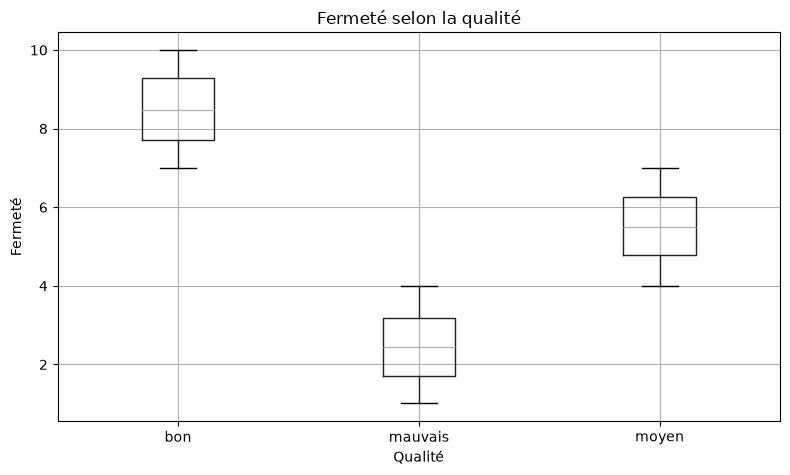

In [74]:
df.boxplot(
    column="firmness",
    by="quality",
    figsize=(8, 5)
)

plt.title("Fermeté selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Fermeté")
plt.tight_layout()
plt.show()

La fermeté présente une relation très nette avec la classe de qualité. Les produits de bonne qualité présentent les niveaux de fermeté les plus élevés, principalement compris entre 7 et 10, avec une médiane proche de 8,5. La classe « moyen » présente des valeurs intermédiaires, comprises approximativement entre 4 et 7, avec une médiane proche de 5,5. Enfin, la classe « mauvais » se caractérise par les niveaux de fermeté les plus faibles, compris entre 1 et 4, avec une médiane proche de 2,4.

Les trois distributions sont clairement séparées, ce qui indique que la fermeté constitue une variable fortement discriminante pour la classification de la qualité. Cette évolution est cohérente avec le processus de maturation : à mesure que la qualité se dégrade, la banane devient progressivement plus molle.

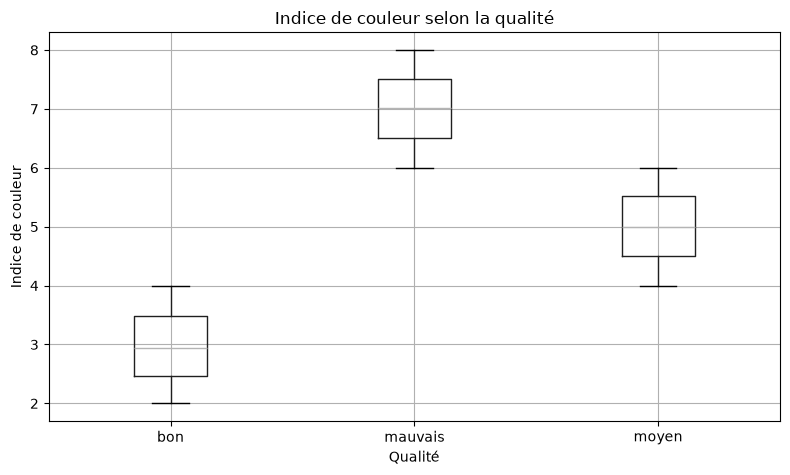

In [75]:
df.boxplot(
    column="color_index",
    by="quality",
    figsize=(8, 5)
)

plt.title("Indice de couleur selon la qualité")
plt.suptitle("")
plt.xlabel("Qualité")
plt.ylabel("Indice de couleur")
plt.tight_layout()
plt.show()

L'indice de couleur présente une relation très nette avec la classe de qualité. Les produits de bonne qualité présentent les indices de couleur les plus faibles, principalement compris entre 2 et 4, avec une médiane proche de 3. La classe « moyen » présente des valeurs intermédiaires, comprises approximativement entre 4 et 6, avec une médiane proche de 5. Enfin, la classe « mauvais » se caractérise par les indices de couleur les plus élevés, compris entre 6 et 8, avec une médiane proche de 7.

Les trois distributions sont clairement séparées, ce qui indique que l'indice de couleur constitue une variable fortement discriminante pour la classification de la qualité. Cette évolution est cohérente avec le processus de maturation des bananes : l'indice de couleur augmente progressivement lorsque le fruit passe d'un état vert à un état plus mûr, puis à un état avancé de maturation.

analyse des corrélations

In [76]:
correlation_matrix = df.select_dtypes(include="number").corr()

correlation_matrix

,temperature,humidity,ethylene,O2,CO2,days,brix,pH,firmness,color_index
temperature,1.000000,-0.047172,0.105188,0.084080,0.098691,0.095033,0.095929,-0.092707,-0.100407,0.086422
humidity,-0.047172,1.000000,-0.317626,-0.331791,-0.333665,-0.307928,-0.311343,0.324712,0.312640,-0.303239
ethylene,0.105188,-0.317626,1.000000,0.862203,0.869883,0.865054,0.865639,-0.870807,-0.873985,0.869826
O2,0.084080,-0.331791,0.862203,1.000000,0.858998,0.853622,0.853931,-0.857319,-0.855257,0.856163
CO2,0.098691,-0.333665,0.869883,0.858998,1.000000,0.860265,0.861263,-0.860509,-0.864761,0.862831
days,0.095033,-0.307928,0.865054,0.853622,0.860265,1.000000,0.992859,-0.865706,-0.882731,0.886466
brix,0.095929,-0.311343,0.865639,0.853931,0.861263,0.992859,1.000000,-0.866488,-0.881747,0.885612
pH,-0.092707,0.324712,-0.870807,-0.857319,-0.860509,-0.865706,-0.866488,1.000000,0.872580,-0.871228
firmness,-0.100407,0.312640,-0.873985,-0.855257,-0.864761,-0.882731,-0.881747,0.872580,1.000000,-0.892045
color_index,0.086422,-0.303239,0.869826,0.856163,0.862831,0.886466,0.885612,-0.871228,-0.892045,1.000000


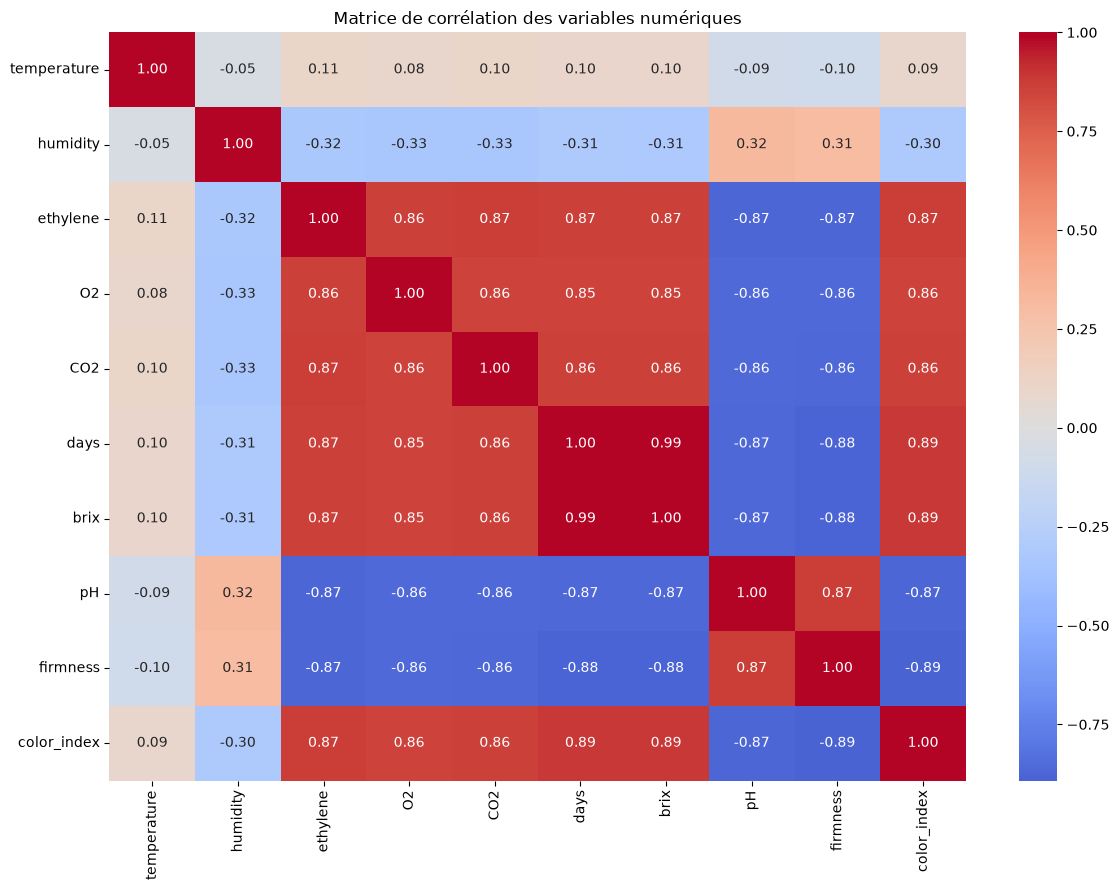

In [77]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

La matrice de corrélation met en évidence plusieurs relations importantes entre les variables numériques du jeu de données.

La température présente des corrélations très faibles avec les autres variables, avec des coefficients proches de zéro. Elle semble donc relativement indépendante des autres mesures dans le jeu de données considéré.

L'humidité présente quant à elle des corrélations modérées avec plusieurs variables. Elle est notamment négativement corrélée à l'éthylène, à l'O2, au CO2, à la durée de stockage, au Brix et à l'indice de couleur, avec des coefficients compris approximativement entre -0,30 et -0,33. Elle présente également des corrélations positives modérées avec le pH et la fermeté.

Une forte corrélation positive est observée entre l'éthylène, l'O2, le CO2, la durée de stockage, le Brix et l'indice de couleur. Plusieurs coefficients sont supérieurs à 0,85 et certains sont proches de 1. Par exemple, la corrélation entre la durée de stockage et le Brix est très élevée, avec un coefficient proche de 0,99. Cela indique que ces variables évoluent de manière très similaire dans le jeu de données.

Le pH et la fermeté présentent également une forte corrélation positive. À l'inverse, ces deux variables sont fortement corrélées négativement avec l'éthylène, l'O2, le CO2, la durée de stockage, le Brix et l'indice de couleur. Ces relations traduisent notamment l'évolution conjointe des différents indicateurs au cours du processus de maturation.

Cette analyse met donc en évidence une certaine **redondance entre plusieurs variables explicatives**. Certaines variables apportent des informations très similaires au modèle. Cette observation devra être prise en compte lors de la phase de modélisation, notamment pour analyser l'importance des variables et comparer les performances des différents modèles.

Enfin, il convient de rappeler qu'une forte corrélation ne signifie pas nécessairement une relation de causalité. De plus, le jeu de données étant synthétique et construit à partir de règles prédéfinies, certaines corrélations élevées sont directement liées à la manière dont les observations ont été générées.

In [78]:
quality_means = (
    df.groupby("quality")
    .mean(numeric_only=True)
    .T
)

quality_means

quality,bon,mauvais,moyen
temperature,13.513993,14.588713,13.682460
humidity,90.054727,79.807980,89.113353
ethylene,0.554867,14.976393,5.672013
O2,3.518607,15.555207,7.479180
CO2,3.496313,15.078167,7.503220
days,6.854013,32.509233,19.435960
brix,8.928187,21.501713,14.956093
pH,5.242433,3.994880,4.745280
firmness,8.490700,2.456533,5.509653
color_index,2.969213,7.007973,4.998367


L'analyse des moyennes par classe confirme les différences observées précédemment dans les diagrammes en boîte. Les variables liées à la maturation présentent une évolution particulièrement nette entre les trois niveaux de qualité.

Pour la classe « bon », les conditions restent proches des conditions optimales : faible concentration en éthylène (0,55 ppm), faibles concentrations en O2 et CO2 (environ 3,5 %), durée de stockage courte (6,85 jours), faible Brix (8,93), pH élevé (5,24), forte fermeté (8,49) et faible indice de couleur (2,97).

La classe « moyen » présente des valeurs intermédiaires pour la majorité de ces variables : 5,67 ppm d'éthylène, environ 7,5 % d'O2 et de CO2, 19,44 jours de stockage, un Brix de 14,96, un pH de 4,75, une fermeté de 5,51 et un indice de couleur proche de 5.

Enfin, la classe « mauvais » présente les caractéristiques associées à un stade de maturation plus avancé : forte concentration en éthylène (14,98 ppm), concentrations élevées en O2 et CO2, durée de stockage importante (32,51 jours), Brix élevé (21,50), pH faible (3,99), faible fermeté (2,46) et indice de couleur élevé (7,01).

La température varie relativement peu entre les classes, avec des moyennes comprises entre environ 13,5 °C et 14,6 °C. L'humidité présente également des différences plus modérées que les autres variables.

Dans l'ensemble, cette analyse confirme que les variables `ethylene`, `O2`, `CO2`, `days`, `brix`, `pH`, `firmness` et `color_index` présentent des différences importantes entre les classes de qualité. Ces résultats sont cohérents avec les boxplots et avec les règles utilisées pour générer le jeu de données synthétique.

In [79]:
from scipy.stats import f_oneway

anova_results = []

for column in numeric_columns:
    groups = [
        df.loc[df["quality"] == quality, column]
        for quality in ["bon", "moyen", "mauvais"]
    ]

    statistic, p_value = f_oneway(*groups)

    anova_results.append({
        "variable": column,
        "F_statistic": statistic,
        "p_value": p_value
    })

anova_results = (
    pd.DataFrame(anova_results)
    .sort_values("p_value")
)

anova_results

,variable,F_statistic,p_value
3,O2,13102.715465,0.000000e+00
2,ethylene,15551.158962,0.000000e+00
5,days,16226.870215,0.000000e+00
4,CO2,14180.578439,0.000000e+00
6,brix,15966.870574,0.000000e+00
7,pH,14426.253971,0.000000e+00
9,color_index,18043.150133,0.000000e+00
8,firmness,17983.701836,0.000000e+00
1,humidity,336.644791,5.740261e-137
0,temperature,25.996652,5.950671e-12


In [80]:
anova_results["significant"] = anova_results["p_value"] < 0.05

anova_results

,variable,F_statistic,p_value,significant
3,O2,13102.715465,0.000000e+00,True
2,ethylene,15551.158962,0.000000e+00,True
5,days,16226.870215,0.000000e+00,True
4,CO2,14180.578439,0.000000e+00,True
6,brix,15966.870574,0.000000e+00,True
7,pH,14426.253971,0.000000e+00,True
9,color_index,18043.150133,0.000000e+00,True
8,firmness,17983.701836,0.000000e+00,True
1,humidity,336.644791,5.740261e-137,True
0,temperature,25.996652,5.950671e-12,True


### Résultats du test ANOVA

Le test ANOVA à un facteur a été appliqué afin de déterminer si les moyennes des variables numériques diffèrent significativement entre les trois classes de qualité : « bon », « moyen » et « mauvais ».

Les résultats montrent que **toutes les variables étudiées présentent une différence statistiquement significative entre les groupes**, avec des valeurs de p largement inférieures au seuil de signification de 5 % (`p < 0,05`).

Les variables présentant les statistiques F les plus élevées sont notamment `color_index` (F ≈ 18 043), `firmness` (F ≈ 17 984), `days` (F ≈ 16 227), `brix` (F ≈ 15 967) et `ethylene` (F ≈ 15 551). Elles présentent donc des différences particulièrement marquées entre les classes.

Les variables `O2`, `CO2` et `pH` présentent également des statistiques F très élevées, confirmant leur forte capacité à différencier les niveaux de qualité. L'humidité présente une statistique F plus faible (F ≈ 336,64), mais sa valeur de p reste extrêmement faible (`p ≈ 5,74 × 10⁻¹³⁷`), indiquant que les différences entre les groupes sont néanmoins statistiquement significatives.

La température présente la statistique F la plus faible parmi les variables étudiées (F ≈ 26,00), mais reste elle aussi statistiquement significative (`p ≈ 5,95 × 10⁻¹²`).

Ainsi, au seuil de 5 %, l'hypothèse nulle d'égalité des moyennes entre les trois groupes est rejetée pour **l'ensemble des variables**. Ces résultats confirment statistiquement les observations réalisées lors de l'analyse bivariée.

Il convient toutefois de préciser que la significativité statistique ne mesure pas directement l'importance pratique d'une variable pour un modèle de machine learning. De plus, les valeurs extrêmement faibles des p-values sont cohérentes avec le caractère synthétique du jeu de données et avec les règles utilisées pour générer les classes.

In [81]:
from scipy.stats import tukey_hsd

quality_order = ["bon", "moyen", "mauvais"]

tukey_results = {}

for column in numeric_columns:
    groups = [
        df.loc[df["quality"] == quality, column]
        for quality in quality_order
    ]

    result = tukey_hsd(*groups)
    tukey_results[column] = result

tukey_results

{'temperature': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd16c5e20>,
 'humidity': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd1eedcd0>,
 'ethylene': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd1b856a0>,
 'O2': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd1eef1d0>,
 'CO2': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd1fb33b0>,
 'days': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd16db950>,
 'brix': <scipy.stats._hypotests.TukeyHSDResult at 0x1eccfd221b0>,
 'pH': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecbf254ad0>,
 'firmness': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd15a3f20>,
 'color_index': <scipy.stats._hypotests.TukeyHSDResult at 0x1ecd15a2ba0>}

In [82]:
print(tukey_results["temperature"])

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.168     0.545    -0.544     0.207
 (0 - 2)     -1.075     0.000    -1.451    -0.699
 (1 - 0)      0.168     0.545    -0.207     0.544
 (1 - 2)     -0.906     0.000    -1.282    -0.530
 (2 - 0)      1.075     0.000     0.699     1.451
 (2 - 1)      0.906     0.000     0.530     1.282



Le test post-hoc de Tukey montre que la température ne présente pas de différence statistiquement significative entre les classes « bon » et « moyen » (p = 0,545). En revanche, des différences significatives sont observées entre « bon » et « mauvais » ainsi qu'entre « moyen » et « mauvais » (p < 0,001 dans les deux cas).

La température permet donc principalement de distinguer la classe « mauvais » des deux autres classes, tandis que les classes « bon » et « moyen » présentent des niveaux de température relativement proches.

In [83]:
tukey_summary = []

for column, result in tukey_results.items():
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        tukey_summary.append({
            "variable": column,
            "group1": quality_order[i],
            "group2": quality_order[j],
            "mean_diff": result.statistic[i, j],
            "p_value": result.pvalue[i, j],
            "significant": result.pvalue[i, j] < 0.05
        })

tukey_summary = pd.DataFrame(tukey_summary)

tukey_summary

,variable,group1,group2,mean_diff,p_value,significant
0,temperature,bon,moyen,-0.168467,5.448462e-01,False
1,temperature,bon,mauvais,-1.074720,6.958056e-11,True
2,temperature,moyen,mauvais,-0.906253,5.031518e-08,True
3,humidity,bon,moyen,0.941373,7.898130e-02,False
4,humidity,bon,mauvais,10.246747,9.193757e-13,True
5,humidity,moyen,mauvais,9.305373,9.193757e-13,True
6,ethylene,bon,moyen,-5.117147,9.193757e-13,True
7,ethylene,bon,mauvais,-14.421527,9.193757e-13,True
8,ethylene,moyen,mauvais,-9.304380,9.193757e-13,True
9,O2,bon,moyen,-3.960573,9.193757e-13,True


### Résultats du test post-hoc de Tukey

À la suite de l'ANOVA, un test post-hoc de Tukey a été réalisé afin d'identifier précisément les paires de classes présentant des différences significatives.

Sur les 30 comparaisons réalisées, 28 présentent une différence statistiquement significative au seuil de 5 %. Les seules comparaisons ne présentant pas de différence significative concernent la température entre les classes « bon » et « moyen » (`p = 0,545`) ainsi que l'humidité entre ces mêmes classes (`p ≈ 0,079`).

Pour l'éthylène, l'O2, le CO2, la durée de stockage, le Brix, le pH, la fermeté et l'indice de couleur, les trois paires de classes (« bon–moyen », « bon–mauvais » et « moyen–mauvais ») présentent toutes des différences statistiquement significatives (`p < 0,05`).

Ces résultats confirment que ces huit variables présentent des distributions significativement différentes entre les trois niveaux de qualité. Elles constituent donc des variables particulièrement discriminantes dans le contexte du jeu de données étudié.

La température et l'humidité présentent toutefois un comportement légèrement différent : elles permettent de distinguer la classe « mauvais » des classes « bon » et « moyen », mais ne permettent pas de différencier significativement « bon » et « moyen » selon le test de Tukey.

Dans l'ensemble, les résultats du test post-hoc confirment les observations issues des boxplots et de l'analyse des moyennes. Ils montrent que les caractéristiques liées à la maturation et à l'état physiologique de la banane sont fortement différenciées entre les trois classes de qualité.

In [84]:
from sklearn.model_selection import train_test_split

X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (3600, 10)
X_test  : (900, 10)
y_train : (3600,)
y_test  : (900,)


In [85]:
print("Répartition de y_train :")
print(y_train.value_counts())

print("\nRépartition de y_test :")
print(y_test.value_counts())

Répartition de y_train :
quality
mauvais    1200
bon        1200
moyen      1200
Name: count, dtype: int64

Répartition de y_test :
quality
moyen      300
bon        300
mauvais    300
Name: count, dtype: int64


## 4. Préparation des données pour la modélisation

Random Forest comme modèle baseline. Il est particulièrement adapté ici parce qu'il fonctionne bien avec des variables numériques, ne nécessite pas de normalisation et permet ensuite d'analyser l'importance des variables.

Les données sont séparées en deux sous-ensembles :

- 80 % pour l'entraînement des modèles ;
- 20 % pour leur évaluation.

La séparation est stratifiée afin de conserver la même répartition des trois classes
de qualité dans les ensembles d'entraînement et de test.

In [86]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [87]:
y_pred = rf_model.predict(X_test)

print(y_pred[:10])

['moyen' 'bon' 'bon' 'moyen' 'moyen' 'bon' 'mauvais' 'moyen' 'moyen' 'bon']


## 6. Évaluation du modèle

In [88]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000


### Évaluation initiale du modèle Random Forest

Le premier modèle de classification utilisé est un algorithme **Random Forest**. Il a été entraîné sur 80 % des observations et évalué sur les 20 % restantes, avec une séparation stratifiée afin de conserver une répartition équilibrée des trois classes de qualité.

Les résultats obtenus sur l'ensemble de test sont les suivants :

| Métrique | Score |
|---|---:|
| Accuracy | 1.0000 |
| Precision | 1.0000 |
| Recall | 1.0000 |
| F1-score | 1.0000 |

Le modèle obtient ainsi une classification parfaite sur l'ensemble de test. Cependant, ces résultats doivent être interprétés avec prudence. Le jeu de données utilisé dans cette première expérimentation est synthétique et les classes de qualité ont été générées à partir de règles définissant des plages de valeurs associées aux différents niveaux de qualité.

La performance de 100 % obtenue reflète donc principalement la capacité du modèle à retrouver les relations présentes dans ces règles de génération. Elle ne constitue pas une preuve de performance sur des données réelles issues de capteurs IoT.

Cette première expérimentation doit ainsi être considérée comme une **validation technique de la chaîne de traitement et de l'architecture ML**, et non comme une validation expérimentale du système dans des conditions réelles.

Une validation ultérieure sur des données réelles collectées à partir de capteurs et d'observations de qualité des bananes sera nécessaire afin d'évaluer la capacité de généralisation du modèle.

In [89]:
## 7. Matrice de confusion

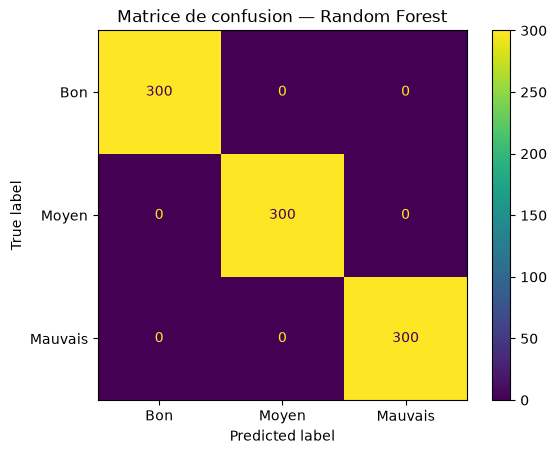

In [90]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["bon", "moyen", "mauvais"],
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Bon", "Moyen", "Mauvais"],
)

disp.plot()
plt.title("Matrice de confusion — Random Forest")
plt.show()

### Interprétation de la matrice de confusion

La matrice de confusion du modèle **Random Forest** présente une classification parfaite des observations du jeu de test.

Sur les **900 observations** utilisées pour l'évaluation :

- les **300 observations de la classe Bon** ont toutes été correctement classées comme *Bon* ;
- les **300 observations de la classe Moyen** ont toutes été correctement classées comme *Moyen* ;
- les **300 observations de la classe Mauvais** ont toutes été correctement classées comme *Mauvais*.

Aucune observation n'a été affectée à une classe incorrecte. La matrice de confusion est donc entièrement diagonale, avec 300 observations correctement classées pour chacune des trois catégories.

Ces résultats sont cohérents avec les métriques précédemment obtenues : **accuracy, précision, rappel et F1-score atteignent tous 100 %** sur le jeu de test.

Cependant, cette performance doit être interprétée avec prudence. Le jeu de données étant synthétique et les classes ayant été générées à partir de règles définissant les conditions de qualité des bananes, le modèle peut retrouver très facilement les relations présentes dans les données. Cette matrice de confusion constitue donc principalement une **validation technique de la chaîne de classification**, et non une preuve de performance sur des données réelles issues de capteurs IoT.

## 8. Importance des variables

In [91]:
feature_importance = pd.DataFrame({
    "variable": X_train.columns,
    "importance": rf_model.feature_importances_,
})

feature_importance = (
    feature_importance
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance

,variable,importance
0,ethylene,0.232574
1,CO2,0.205131
2,days,0.178292
3,O2,0.169797
4,firmness,0.102198
5,color_index,0.072463
6,pH,0.034758
7,brix,0.004716
8,humidity,0.000054
9,temperature,0.000017


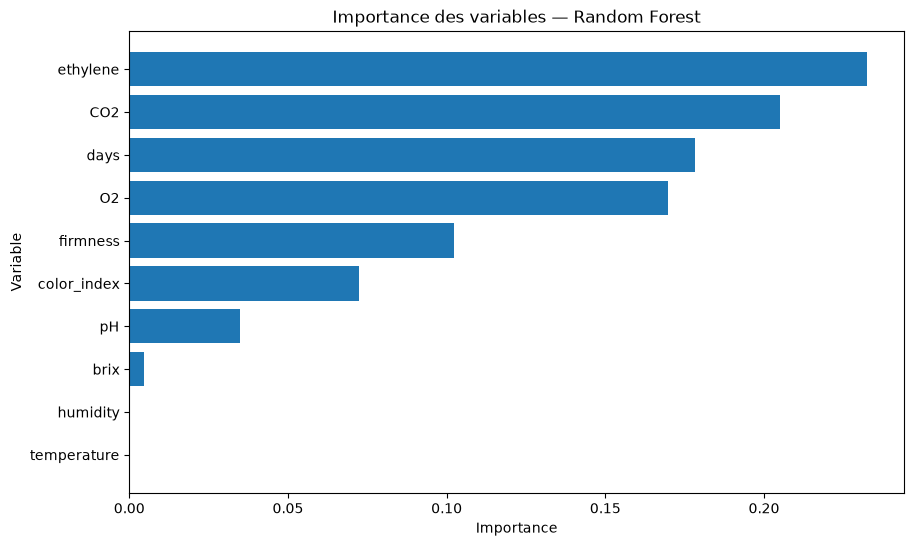

In [92]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["variable"],
    feature_importance["importance"],
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Variable")
plt.title("Importance des variables — Random Forest")

plt.show()

### Interprétation de l'importance des variables

L'analyse de l'importance des variables obtenue à partir du modèle Random Forest met en évidence une contribution différente des caractéristiques utilisées pour la classification de la qualité des bananes.

La variable **éthylène** apparaît comme la plus importante, avec une contribution d'environ **23 %**. Elle est suivie par le **CO₂** (environ 20,5 %), la **durée de stockage** (`days`, environ 18 %) et l'**O₂** (environ 17 %). La **fermeté** représente également une contribution notable, avec environ 10 %, tandis que l'**indice de couleur** contribue à hauteur d'environ 7,5 %.

Le **pH** présente une importance plus faible, tandis que le **Brix**, l'**humidité** et la **température** contribuent très peu aux décisions du modèle dans cette expérimentation.

Ces résultats sont globalement cohérents avec l'analyse exploratoire et statistique réalisée précédemment. Les variables liées à la maturation et à l'évolution de l'état du fruit, notamment l'éthylène, les gaz respiratoires, la durée de stockage, la fermeté et la couleur, présentent effectivement des différences importantes entre les classes de qualité.

Il convient néanmoins de préciser que l'importance des variables fournie par Random Forest mesure leur contribution aux décisions du modèle et ne permet pas, à elle seule, d'établir une relation causale. De plus, certaines variables sont fortement corrélées entre elles dans le jeu de données synthétique. Leur importance peut donc être répartie entre plusieurs variables corrélées.

Enfin, ces résultats doivent être considérés comme exploratoires, puisque le jeu de données utilisé est synthétique. Une analyse sur des données réelles issues de capteurs permettrait de vérifier si cette hiérarchie des variables se maintient dans des conditions expérimentales réelles.

## 5. Comparaison avec un modèle de Gradient Boosting

Afin de comparer les performances du Random Forest avec une autre
approche de classification sur données tabulaires, un modèle
HistGradientBoosting est entraîné sur les mêmes données d'apprentissage.

L'objectif est de vérifier si les performances obtenues avec le
Random Forest sont confirmées par un autre algorithme.

In [93]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    random_state=42,
)

hgb_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

In [94]:
y_pred_hgb = hgb_model.predict(X_test)

print(y_pred_hgb[:10])

['moyen' 'bon' 'bon' 'moyen' 'moyen' 'bon' 'mauvais' 'moyen' 'moyen' 'bon']


In [95]:
accuracy_hgb = accuracy_score(y_test, y_pred_hgb)

precision_hgb = precision_score(
    y_test,
    y_pred_hgb,
    average="weighted",
)

recall_hgb = recall_score(
    y_test,
    y_pred_hgb,
    average="weighted",
)

f1_hgb = f1_score(
    y_test,
    y_pred_hgb,
    average="weighted",
)

print(f"Accuracy  : {accuracy_hgb:.4f}")
print(f"Precision : {precision_hgb:.4f}")
print(f"Recall    : {recall_hgb:.4f}")
print(f"F1-score  : {f1_hgb:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000


## 6. Comparaison des modèles

Les performances des deux modèles sont regroupées afin de faciliter leur
comparaison sur le même jeu de test.

In [96]:
model_comparison = pd.DataFrame({
    "Modèle": [
        "Random Forest",
        "HistGradientBoosting",
    ],
    "Accuracy": [
        accuracy,
        accuracy_hgb,
    ],
    "Precision": [
        precision,
        precision_hgb,
    ],
    "Recall": [
        recall,
        recall_hgb,
    ],
    "F1-score": [
        f1,
        f1_hgb,
    ],
})

model_comparison

,Modèle,Accuracy,Precision,Recall,F1-score
0,Random Forest,1.0,1.0,1.0,1.0
1,HistGradientBoosting,1.0,1.0,1.0,1.0


Les deux modèles évalués, Random Forest et HistGradientBoosting, obtiennent des performances identiques sur le jeu de test, avec une accuracy, une précision, un rappel et un F1-score de 1.0000.

Ces résultats indiquent que les trois classes de qualité sont parfaitement séparables dans le jeu de données synthétique utilisé. Ils sont cohérents avec les analyses statistiques précédentes, qui ont montré de fortes différences entre les classes pour plusieurs variables.

Cependant, ces performances ne doivent pas être interprétées comme une preuve d'une performance équivalente sur des données réelles. Le dataset ayant été généré à partir de règles définissant directement les différentes catégories de qualité, les modèles apprennent des relations très structurées entre les variables et la variable cible.

Les résultats constituent donc principalement une validation du pipeline de classification et de la faisabilité de l'approche. Une évaluation sur les données réellement collectées par les capteurs IoT sera nécessaire pour mesurer les performances du système dans des conditions réelles.

## 7. Matrice de confusion — HistGradientBoosting

La matrice de confusion permet d'analyser les prédictions du modèle
pour chacune des trois classes de qualité : Bon, Moyen et Mauvais.

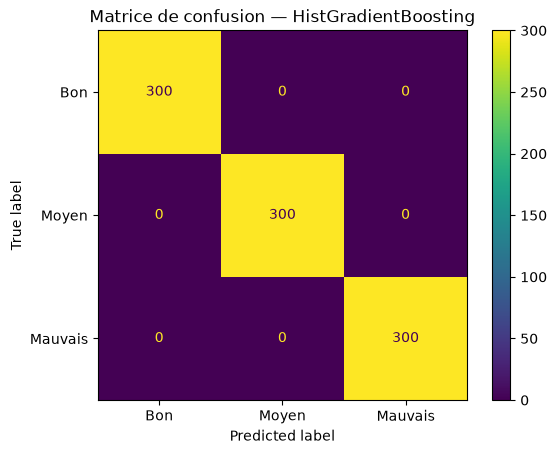

In [98]:


cm_hgb = confusion_matrix(
    y_test,
    y_pred_hgb,
    labels=["bon", "moyen", "mauvais"],
)

disp_hgb = ConfusionMatrixDisplay(
    confusion_matrix=cm_hgb,
    display_labels=["Bon", "Moyen", "Mauvais"],
)

disp_hgb.plot()

plt.title("Matrice de confusion — HistGradientBoosting")
plt.show()

La matrice de confusion du modèle HistGradientBoosting montre que les 900 observations du jeu de test sont correctement classées. Les 300 observations de la classe « Bon », les 300 observations de la classe « Moyen » et les 300 observations de la classe « Mauvais » sont toutes correctement identifiées.

Aucune confusion entre les différentes classes n'est observée sur ce jeu de test. Le modèle atteint ainsi un taux de classification correct de 100 % sur les données synthétiques utilisées.

Comme pour le Random Forest, ce résultat doit toutefois être interprété avec prudence. La séparation parfaite des classes est liée à la structure fortement déterministe du dataset synthétique. Elle ne permet pas encore de conclure à une performance équivalente sur les données réelles issues des capteurs IoT.

## 8. Validation croisée

Afin de vérifier la stabilité des performances des modèles, une validation
croisée stratifiée en 5 plis est réalisée sur les données d'entraînement.

Cette approche permet d'évaluer chaque modèle sur plusieurs sous-ensembles
des données et de calculer une moyenne ainsi qu'un écart-type des scores.

In [100]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

In [102]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted",
}

rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

hgb_cv = cross_validate(
    hgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

In [103]:
cv_results = pd.DataFrame({
    "Modèle": [
        "Random Forest",
        "HistGradientBoosting",
    ],
    "Accuracy moyenne": [
        rf_cv["test_accuracy"].mean(),
        hgb_cv["test_accuracy"].mean(),
    ],
    "Accuracy std": [
        rf_cv["test_accuracy"].std(),
        hgb_cv["test_accuracy"].std(),
    ],
    "F1 moyen": [
        rf_cv["test_f1"].mean(),
        hgb_cv["test_f1"].mean(),
    ],
    "F1 std": [
        rf_cv["test_f1"].std(),
        hgb_cv["test_f1"].std(),
    ],
})

cv_results

,Modèle,Accuracy moyenne,Accuracy std,F1 moyen,F1 std
0,Random Forest,1.0,0.0,1.0,0.0
1,HistGradientBoosting,1.0,0.0,1.0,0.0


## 9. Importance des variables par permutation

L'importance des variables obtenue avec Random Forest dépend de la
construction des arbres et peut être influencée par la présence de
variables corrélées.

Une importance par permutation est donc utilisée afin d'évaluer
l'impact de chaque variable sur les performances du modèle.

In [107]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1_weighted",
    n_jobs=-1,
)

print("Calcul terminé")

Calcul terminé


In [108]:
permutation_results = pd.DataFrame({
    "variable": X_test.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std,
})

permutation_results = (
    permutation_results
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

permutation_results

,variable,importance_mean,importance_std
0,temperature,0.0,0.0
1,humidity,0.0,0.0
2,ethylene,0.0,0.0
3,O2,0.0,0.0
4,CO2,0.0,0.0
5,days,0.0,0.0
6,brix,0.0,0.0
7,pH,0.0,0.0
8,firmness,0.0,0.0
9,color_index,0.0,0.0


In [110]:
permutation_results = pd.DataFrame({
    "variable": X_test.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std,
})

permutation_results = (
    permutation_results
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

print(permutation_results)

      variable  importance_mean  importance_std
0  temperature              0.0             0.0
1     humidity              0.0             0.0
2     ethylene              0.0             0.0
3           O2              0.0             0.0
4          CO2              0.0             0.0
5         days              0.0             0.0
6         brix              0.0             0.0
7           pH              0.0             0.0
8     firmness              0.0             0.0
9  color_index              0.0             0.0


In [111]:
top_features = [
    "ethylene",
    "CO2",
    "days",
    "O2",
    "firmness",
]

X_train_top = X_train[top_features]
X_test_top = X_test[top_features]

rf_top = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)

rf_top.fit(X_train_top, y_train)

y_pred_top = rf_top.predict(X_test_top)

accuracy_top = accuracy_score(y_test, y_pred_top)
f1_top = f1_score(
    y_test,
    y_pred_top,
    average="weighted",
)

print(f"Accuracy : {accuracy_top:.4f}")
print(f"F1-score : {f1_top:.4f}")

Accuracy : 1.0000
F1-score : 1.0000


In [112]:
feature_comparison = pd.DataFrame({
    "Configuration": [
        "10 variables",
        "5 variables",
    ],
    "Nombre de variables": [
        len(FEATURE_COLUMNS),
        len(top_features),
    ],
    "Accuracy": [
        accuracy,
        accuracy_top,
    ],
    "F1-score": [
        f1,
        f1_top,
    ],
})

print(feature_comparison)

  Configuration  Nombre de variables  Accuracy  F1-score
0  10 variables                   10       1.0       1.0
1   5 variables                    5       1.0       1.0


Une expérience de réduction du nombre de variables a été réalisée afin d'évaluer si l'ensemble des variables était nécessaire à la classification.

Les cinq variables présentant les plus fortes importances selon le Random Forest (`ethylene`, `CO2`, `days`, `O2` et `firmness`) ont été utilisées pour entraîner un nouveau modèle.

Le modèle obtenu avec seulement cinq variables conserve une Accuracy de 1.0000 et un F1-score de 1.0000, identiques aux performances obtenues avec les dix variables initiales.

Ce résultat montre que, dans le dataset synthétique étudié, un sous-ensemble de cinq variables contient déjà suffisamment d'information pour distinguer les trois niveaux de qualité.

Cependant, cette observation ne justifie pas encore la suppression définitive des autres variables. Le dataset présente de fortes corrélations entre plusieurs variables, et les performances parfaites résultent notamment des règles utilisées lors de sa génération. La sélection finale des variables devra donc être réévaluée sur les données réelles issues des capteurs IoT.